In [ ]:
import csv

import marimo as mo
import matplotlib.pyplot as plt
import numpy as np

import drilleng as de

plt.rcParams.update(
    {
        "figure.dpi": 130,
        "font.size": 9,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.unicode_minus": False,
    }
)

DATA = "data/formation_layers.csv"

with open(DATA, encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
for r in rows:
    for k in r:
        if k != "formation":
            r[k] = float(r[k])

tops = np.array([r["top_m"] for r in rows])
n_layers = len(rows)
total_depth = rows[-1]["base_m"]
print(f"{n_layers} layers, 0 - {total_depth:.0f} m")

14 layers, 0 - 5800 m


# 02 — Rock Mechanics & Mud Weight Window（岩石力学与泥浆密度窗口）

本章把 SPE *Fundamentals of Drilling Engineering* 第 2 章（地应力与钻井中的岩石力学）的
一条主链，用自己的话重新推一遍，并做成可重算的代码：

1. 由密度剖面积分得到**上覆岩层压力** $P_o$
2. 由压力系数得到**孔隙压力** $P_p$
3. 由单轴应变关系得到**最小水平主应力** $\sigma_h$
4. 由 Kirsch 解与拉伸破坏得到**破裂压力** $P_f$
5. 由 Kirsch 解与 Mohr-Coulomb 判据得到**坍塌压力** $P_c$
6. 组合成**泥浆密度窗口**（安全密度上下限）

**数据声明**：`data/formation_layers.csv` 中的层序与参数为示例设计取值，**不是实测数据**，
不含任何井位信息。用于本仓库的算例演示。

## 0. 数据与网格

层序自上而下是连续的，所以只需要每层的顶深就能确定任意深度属于哪一层
（`searchsorted`）。深度网格取 10 m，覆盖 0–5800 m。

**网格必须包含地表 0 m**：上覆压力是自地表向下的累积积分，第一个点必须是 0。
如果网格从 10 m 开始，积分器会把 10 m 当作新的零点，10 m 处 σ_v 变成 0，
整条应力曲线都会被拉偏（这是一个真实踩过的坑）。

In [ ]:
z = np.arange(0.0, total_depth + 0.01, 10.0)


def layer_series(key):
    """Layer property sampled on the depth grid `z`."""
    idx = np.searchsorted(tops, z, side="right") - 1
    idx = np.clip(idx, 0, n_layers - 1)
    return np.array([rows[i][key] for i in idx])


pp_coeff = layer_series("pp_coeff")
rho_bulk = layer_series("rho_gcc") * 1000.0  # kg/m3
biot = layer_series("biot")
poisson = layer_series("poisson")
cohesion = layer_series("c_mpa") * 1e6  # Pa
phi = layer_series("phi_deg")

In [ ]:
mo.ui.table(
    [
        {
            "formation": r["formation"],
            "top (m)": f"{r['top_m']:.0f}",
            "base (m)": f"{r['base_m']:.0f}",
            "Pp coeff": f"{r['pp_coeff']:.2f}",
            "rho (g/cc)": f"{r['rho_gcc']:.2f}",
            "biot": f"{r['biot']:.2f}",
            "nu": f"{r['poisson']:.2f}",
            "c (MPa)": f"{r['c_mpa']:.0f}",
            "phi (deg)": f"{r['phi_deg']:.0f}",
        }
        for r in rows
    ],
    selection=None,
)

[{'formation': '遂宁组-沙溪庙组', 'top (m)': '0', 'base (m)': '1450', 'Pp coeff': '1.00', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.30', 'c (MPa)': '18', 'phi (deg)': '25'}, {'formation': '凉高山组-自流井组', 'top (m)': '1450', 'base (m)': '1850', 'Pp coeff': '1.30', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.29', 'c (MPa)': '20', 'phi (deg)': '28'}, {'formation': '须家河组', 'top (m)': '1850', 'base (m)': '2350', 'Pp coeff': '1.40', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '22', 'phi (deg)': '30'}, {'formation': '雷口坡组', 'top (m)': '2350', 'base (m)': '2750', 'Pp coeff': '1.40', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '22', 'phi (deg)': '30'}, {'formation': '嘉五段-嘉三段', 'top (m)': '2750', 'base (m)': '3320', 'Pp coeff': '1.40', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '25', 'phi (deg)': '32'}, {'formation': '嘉二段-嘉一段', 'top (m)': '3320', 'base (m)': '3600', 'Pp coeff': '2.00', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.35', 'c (MPa)': '24', 'phi (deg)': '25'}, {'formation': '飞仙关组', 'top (m)': '3600', 'base (m)': '3970', 'Pp coeff': '1.65', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '28', 'phi (deg)': '35'}, {'formation': '长兴组-龙潭组', 'top (m)': '3970', 'base (m)': '4170', 'Pp coeff': '1.65', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '28', 'phi (deg)': '35'}, {'formation': '茅口组-栖霞组', 'top (m)': '4170', 'base (m)': '4500', 'Pp coeff': '1.80', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.29', 'c (MPa)': '32', 'phi (deg)': '38'}, {'formation': '洗象池组-高台组', 'top (m)': '4500', 'base (m)': '4700', 'Pp coeff': '1.65', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '32', 'phi (deg)': '38'}, {'formation': '龙王庙组', 'top (m)': '4700', 'base (m)': '4820', 'Pp coeff': '1.63', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '35', 'phi (deg)': '40'}, {'formation': '沧浪铺组', 'top (m)': '4820', 'base (m)': '4980', 'Pp coeff': '1.65', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.28', 'c (MPa)': '30', 'phi (deg)': '35'}, {'formation': '筇竹寺组', 'top (m)': '4980', 'base (m)': '5320', 'Pp coeff': '1.65', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.30', 'c (MPa)': '28', 'phi (deg)': '30'}, {'formation': '灯影组', 'top (m)': '5320', 'base (m)': '5800', 'Pp coeff': '1.65', 'rho (g/cc)': '2.65', 'biot': '1.00', 'nu': '0.29', 'c (MPa)': '45', 'phi (deg)': '42'}]

## 1. 上覆岩层压力 $P_o$（overburden / vertical stress）

从定义出发，垂向总应力就是上覆岩柱的重量：

$$ \sigma_v(z) = \int_0^z \rho(z')\, g \, dz' \approx \sum_i \frac{\rho_i+\rho_{i-1}}{2}\, g\, \Delta z $$

没有系数、没有经验式——只要密度是体积密度（bulk density），这个式子就是精确的。
现场常把结果写成当量密度 $\rho_{eq} = P/(g z)$，单位 g/cc，这样不同深度可以横向比较。

In [ ]:
po = np.array(de.overburden_pressure(z, rho_bulk))

zw = z[1:]  # 当量密度在 z = 0 处无定义，后续一律用 z > 0 的网格


def to_gcc(p):
    """Absolute pressure [Pa] -> equivalent density [g/cc], skipping the surface."""
    return p[1:] / (de.G * zw) / 1000.0


po_gcc = to_gcc(po)
print(f"Po at {z[-1]:.0f} m = {po[-1] / 1e6:.2f} MPa  (equivalent density {po_gcc[-1]:.3f} g/cc)")

Po at 5800 m = 150.73 MPa  (equivalent density 2.650 g/cc)


## 2. 孔隙压力 $P_p$（pore pressure）

本仓库采用**压力系数法**：以淡水静液柱为基准，把实测或预测的压力表示成
"正常压力的多少倍"。

$$ P_p = k_p \, \rho_w \, g \, z, \qquad \rho_w = 1000\ \mathrm{kg/m^3} $$

$k_p = 1.0$ 为正常压力；$k_p > 1$ 为异常高压。这样定义的好处是 $k_p$ 直接就等于
孔隙压力的**当量密度数值**（以 g/cc 计），工程上可以一眼判断。

真正的压力预测（Eaton 法、dc 指数、地震层速度）留到以后单独做，本章把 $k_p$ 当作输入。

In [ ]:
pp = np.array([de.pore_pressure_from_coeff(k, zi) for k, zi in zip(pp_coeff, z)])

pp_gcc = to_gcc(pp)
print(f"Pp at {z[-1]:.0f} m = {pp[-1] / 1e6:.2f} MPa  (equivalent density {pp_gcc[-1]:.3f} g/cc)")

Pp at 5800 m = 93.85 MPa  (equivalent density 1.650 g/cc)


## 3. 最小水平主应力 $\sigma_h$

假设地层为横向各向同性、水平方向应变为零（单轴应变条件），由广义胡克定律
与有效应力原理（Biot 系数 $\alpha$）可得：

$$ \sigma_h = \frac{\nu}{1-\nu}\left(\sigma_v - \alpha P_p\right) + \alpha P_p $$

这个式子的物理含义值得说清楚：**驱动水平应力的是垂向有效应力**，而不是垂向总应力。
所以异常高压层（$P_p$ 高）的水平应力也会被抬起来——这正是高压层段钻井窗口变窄的原因。

**局限**：这个式子给出的是 $\sigma_h$（最小值）。它无法区分构造应力造成的各向异性，
所以下面用 $\sigma_H = k_{ani}\,\sigma_h$ 引入一个可调的比值 $k_{ani}$，
默认取 1.0（水平应力各向同性，即完全由重力与孔隙压力控制）。

In [ ]:
sh_min_ani = mo.ui.slider(
    start=1.00, stop=1.30, step=0.01, value=1.00, label="σH / σh 各向异性比"
)
sh_min_ani

&lt;marimo-slider data-initial-value=&#x27;1.0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eσH / σh 各向异性比&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-start=&#x27;1.0&#x27; data-stop=&#x27;1.3&#x27; data-step=&#x27;0.01&#x27; data-steps=&#x27;[]&#x27; data-debounce=&#x27;false&#x27; data-disabled=&#x27;false&#x27; data-orientation=&#x27;&amp;quot;horizontal&amp;quot;&#x27; data-show-value=&#x27;false&#x27; data-include-input=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-slider&gt;

In [ ]:
sh_min = np.array(
    [de.min_horizontal_stress(sv, p, nu, a) for sv, p, nu, a in zip(po, pp, poisson, biot)]
)
sh_max = sh_min_ani.value * sh_min

sh_min_gcc = to_gcc(sh_min)
print(f"sh_min at {z[-1]:.0f} m = {sh_min[-1] / 1e6:.2f} MPa ({sh_min_gcc[-1]:.3f} g/cc)")

sh_min at 5800 m = 117.08 MPa (2.058 g/cc)


## 4. 破裂压力 $P_f$（fracture pressure）

井壁处的环向总应力由 Kirsch 解给出（$\theta$ 自 $\sigma_H$ 方向起算）：

$$ \sigma_\theta = \sigma_H + \sigma_h - 2(\sigma_H-\sigma_h)\cos 2\theta - P_w $$

取 $\theta = 90^\circ$（沿 $\sigma_h$ 方向）得到环向应力**最小**的位置：

$$ \sigma_\theta = 3\sigma_H - \sigma_h - P_w $$

当井筒压力升高、有效环向应力降到 $-\sigma_T$（岩石抗拉强度）时发生拉伸破坏。
在 $\sigma_H = \sigma_h$ 的简化下上式退化为 $P_f = \sigma_h + \sigma_T$，
即"破裂压力就是最小水平主应力加抗拉强度"。本章取 $\sigma_T = 0$（保守下限），
于是 $P_f = \sigma_h$。

In [ ]:
tensile = 0.0  # Pa, 为 0 表示忽略抗拉强度，取保守下限
pf = np.array(
    [de.fracture_pressure(sv, p, nu, a, tensile) for sv, p, nu, a in zip(po, pp, poisson, biot)]
)

pf_gcc = to_gcc(pf)
print(f"Pf at {z[-1]:.0f} m = {pf[-1] / 1e6:.2f} MPa ({pf_gcc[-1]:.3f} g/cc)")

Pf at 5800 m = 117.08 MPa (2.058 g/cc)


## 5. 坍塌压力 $P_c$（collapse / breakout pressure）

井壁失稳的另一侧是**剪切破坏**。在 $\theta = 90^\circ$ 处，井壁的三个有效主应力为：

$$ \sigma_r' = P_w - \alpha P_p, \qquad
   \sigma_\theta' = 3\sigma_H - \sigma_h - P_w - \alpha P_p, \qquad
   \sigma_z' = \sigma_v - \alpha P_p $$

取 Mohr-Coulomb 判据 $\sigma_1' = \sigma_c + N\sigma_3'$，其中

$$ N = \tan^2\!\left(45^\circ + \frac{\phi}{2}\right), \qquad
   \sigma_c = 2c\sqrt{N} $$

令 $\sigma_\theta' \ge N\sigma_r'$ 恰好成立，解出维持井壁稳定所需的**最小**井筒压力：

$$ \boxed{\;P_c = \frac{3\sigma_H - \sigma_h - \sigma_c + \alpha P_p (N-1)}{1+N}\;} $$

注意这一推导里 $\sigma_v$ 没有直接出现——垂向应力是通过 $\sigma_h$ 间接进来的。

**一个必须接受的后果**：算出来的 $P_c$ 可能**低于** $P_p$。这不代表公式错了，
而是说明在该层段剪切破坏不控制窗口下限，孔隙压力才是下限。这种情况应当如实报告，
而不是用 `Pc = max(Pc, Pp)` 之类的夹逼把数修好看——那样会掩盖真正的物理信息。

In [ ]:
pc = np.array(
    [
        de.mohr_coulomb_collapse(shmax, shmin, p, c, ph, a)
        for shmax, shmin, p, c, ph, a in zip(sh_max, sh_min, pp, cohesion, phi, biot)
    ]
)

pc_gcc = to_gcc(pc)
print(f"Pc at {z[-1]:.0f} m = {pc[-1] / 1e6:.2f} MPa ({pc_gcc[-1]:.3f} g/cc)")

Pc at 5800 m = 68.09 MPa (1.197 g/cc)


## 6. 泥浆密度窗口 $[\rho_{lower},\ \rho_{upper}]$

现场不用压力画窗口图，而用**当量密度**，因为这样得出一条与深度无关的"允许泥浆密度带"：

$$ \rho_{eq} = \frac{P}{g\,z} $$

$$ \rho_{lower} = \max(\rho_{eq}(P_p),\ \rho_{eq}(P_c)), \qquad
   \rho_{upper} = \rho_{eq}(P_f) $$

窗口宽度 $\Delta\rho = \rho_{upper} - \rho_{lower}$ 若在某层段趋于 0，就是该井段的
**关键风险点**：往下打必须同时防漏和防溢。

In [ ]:
lo = np.maximum(to_gcc(pp), to_gcc(pc))
hi = to_gcc(pf)
width = hi - lo

i_worst = int(np.argmin(width))
print(f"narrowest window at {zw[i_worst]:.0f} m : {width[i_worst]:.3f} g/cc "
      f"({lo[i_worst]:.3f} - {hi[i_worst]:.3f})")
print(f"median window width: {np.median(width):.3f} g/cc")
print(f"collapse controls the lower bound in {int(np.sum(to_gcc(pc) > to_gcc(pp)))} of {len(zw)} samples")

narrowest window at 4450 m : 0.347 g/cc (1.800 - 2.147)
median window width: 0.486 g/cc
collapse controls the lower bound in 0 of 580 samples


## 7. 成品图：泥浆密度窗口

图注用英文（便于直接用于申请材料），正文用中文。

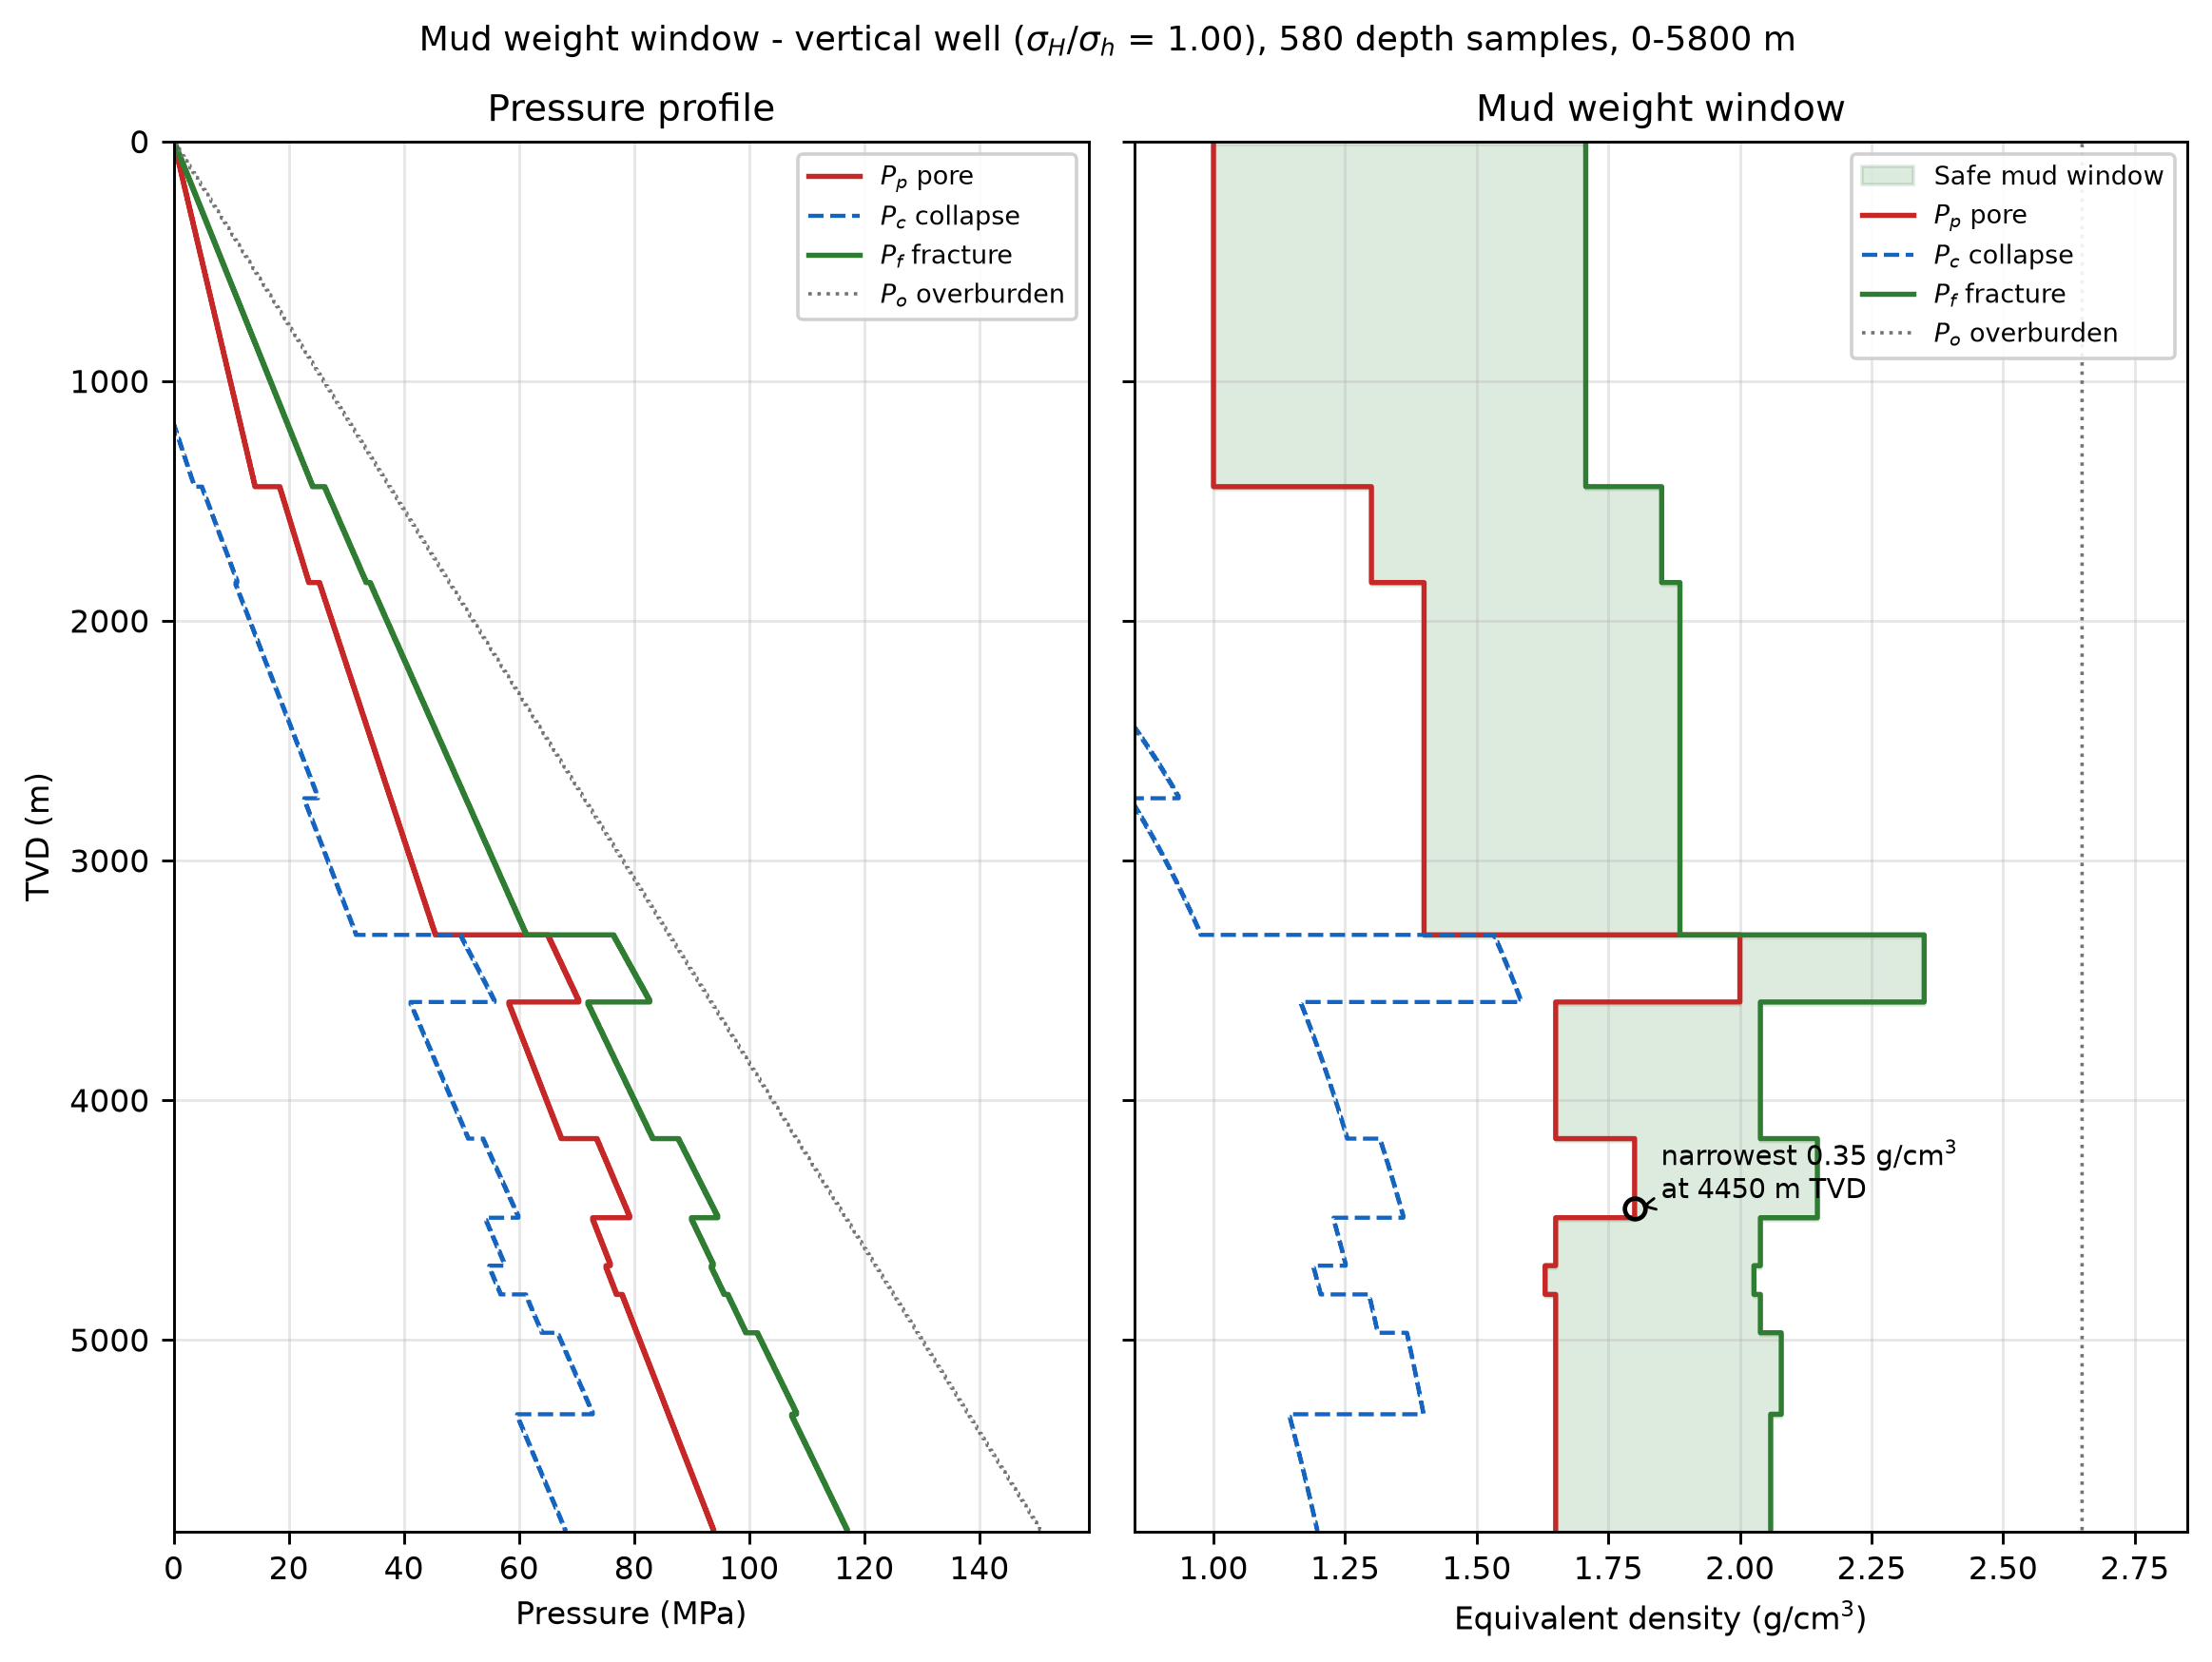

In [ ]:
fig, (axp, axd) = plt.subplots(
    1,
    2,
    figsize=(9.0, 6.8),
    sharey=True,
    gridspec_kw={"width_ratios": [1.0, 1.15]},
)

for ax in (axp, axd):
    ax.set_ylim(zw[-1], 0)
    ax.grid(True, alpha=0.3)

# --- left: absolute pressures -----------------------------------------
axp.plot(pp[1:] / 1e6, zw, color="#c62828", lw=1.5, drawstyle="steps-post", label=r"$P_p$ pore")
axp.plot(pc[1:] / 1e6, zw, color="#1565c0", lw=1.2, ls="--", drawstyle="steps-post", label=r"$P_c$ collapse")
axp.plot(pf[1:] / 1e6, zw, color="#2e7d32", lw=1.5, drawstyle="steps-post", label=r"$P_f$ fracture")
axp.plot(po[1:] / 1e6, zw, color="0.45", lw=1.0, ls=":", drawstyle="steps-post", label=r"$P_o$ overburden")
axp.set_xlabel("Pressure (MPa)")
axp.set_ylabel("TVD (m)")
axp.set_title("Pressure profile")
axp.set_xlim(left=0.0)
axp.legend(loc="upper right", fontsize=7.5, framealpha=0.9)

# --- right: equivalent-density window ---------------------------------
axd.fill_betweenx(
    zw, lo, hi, color="#2e7d32", alpha=0.16, step="post", label="Safe mud window"
)
axd.plot(to_gcc(pp), zw, color="#c62828", lw=1.5, drawstyle="steps-post", label=r"$P_p$ pore")
axd.plot(to_gcc(pc), zw, color="#1565c0", lw=1.2, ls="--", drawstyle="steps-post", label=r"$P_c$ collapse")
axd.plot(to_gcc(pf), zw, color="#2e7d32", lw=1.5, drawstyle="steps-post", label=r"$P_f$ fracture")
axd.plot(to_gcc(po), zw, color="0.45", lw=1.0, ls=":", drawstyle="steps-post", label=r"$P_o$ overburden")

axd.plot(lo[i_worst], zw[i_worst], "o", ms=6, mfc="none", mec="k", mew=1.3, zorder=5)
axd.annotate(
    f"narrowest {width[i_worst]:.2f} g/cm$^3$" + chr(10) + f"at {zw[i_worst]:.0f} m TVD",
    xy=(lo[i_worst], zw[i_worst]),
    xytext=(0.50, 0.24),
    textcoords="axes fraction",
    fontsize=8,
    arrowprops=dict(arrowstyle="->", lw=0.8, color="k"),
)

axd.set_xlabel("Equivalent density (g/cm$^3$)")
axd.set_xlim(0.85, 2.85)
axd.set_title("Mud weight window")
axd.legend(loc="upper right", fontsize=7.5, framealpha=0.9)

fig.suptitle(
    r"Mud weight window - vertical well ($\sigma_H/\sigma_h$ = %.2f), %d depth samples, 0-%.0f m"
    % (sh_min_ani.value, len(zw), zw[-1]),
    fontsize=10,
)
fig.tight_layout()
fig.savefig("figures/mud-window.png", dpi=200, bbox_inches="tight")
fig

## 8. 工程判断

四条可以直接写进汇报的结论（数字都由上面的代码算出，拖动滑块会变）：

1. **各向同性假设下，窗口下限完全由孔隙压力控制。** $\sigma_H/\sigma_h = 1.0$ 时，
   580 个深度采样点的 $P_c$ 全部低于 $P_p$——剪切破坏根本不控制下限。
   拖动滑块到 1.2，才有 34 个点转由 $P_c$ 控制；拉到 1.3，变成 78 个点。
   **结论：构造应力各向异性才是坍塌风险的真正来源，而不是岩石强度参数。**

2. **窗口最窄处跟着高压层走。** 默认参数下窗口宽度在 0.35–0.71 g/cc 之间，
   最窄处 0.347 g/cc 出现在 4450 m（茅口组—栖霞组，$k_p = 1.80$），
   最宽处在地表附近（$k_p = 1.00$）。原因是 $\sigma_h$ 虽然随 $P_p$ 一起抬高，
   但增幅是 $P_p$ 的 $
u/(1-
u) pprox 0.41$ 倍，永远追不上 $P_p$ 本身，
   所以**异常高压必然压缩钻井窗口**。这就是"压力预测不准就是井漏"的定量解释。

3. **把 $\sigma_H/\sigma_h$ 拉到 1.3，最窄点会从 4450 m 跳到 3590 m，
   宽度掉到 0.155 g/cc。** 也就是说，同一套岩石强度参数下，
   仅凭"水平应力是否各向同性"这一个假设，结论就从"窗口够用"变成"几乎没窗口"。
   **模型的敏感性集中在这一项上**，而不是在 $c$、$\phi$ 的取值上。

4. **模型最弱的一环是 $\sigma_h$ 的估计方法。** 单轴应变式只适用于未经受强烈
   构造运动的盆地；要真正落地，必须有漏失试验（LOT/XLOT）或声波+密度反演标定。
   **这句话必须始终跟图一起出现**，否则这张图会被误读成"设计泥浆密度就是这些数"。

同时要说清楚它**不能**做什么：这张图不是施工设计依据，它是公开假设下的一套计算演示。

**还有一处必须交代的局限**：浅层（0–1450 m）给定的内聚力 $c = 18$ MPa 对疏松砂泥岩
明显偏高，按此参数算出的 $P_c$ 甚至为负——数学上意味着"不用泥浆也塌不了"，显然不符合
实际。这不是公式错误，而是**示例参数的局限**：本章的 $c$、$\phi$ 是搬来的设计取值，
没有经过任何岩心或测井标定。所以图中蓝线在浅部落到 0 左侧，应当被理解为
"这套参数在该井段不可信"，而不是"该井段很安全"。

## 9. 自校验

四条断言，全部是针对**模型内部一致性**的硬检查，而不是"看起来对"：

1. 由 $k_p$ 生成的孔隙压力，其当量密度必须精确等于 $k_p$（验证压力→当量密度整条管线）
2. 常密度积分必须与闭式解 $
ho g z$ 一致（验证积分器）
3. 各向同性基线下窗口宽度处处为正、且 $P_f \ge P_p$（验证物理单调性）
4. ppg 换算自洽（验证现场单位转换层）

第 3 条只在基线下校验：把各向异性调到 1.3 本来就该破坏这个不等式，那是模型在
告诉你窗口消失了，而不是程序出错。

In [ ]:
# 1. equivalent density of Pp must reproduce the input coefficient exactly
assert np.max(np.abs(to_gcc(pp) - pp_coeff[1:])) < 1e-12

# 2. constant-density closed form for the overburden
po_check = np.array(de.overburden_pressure([0.0, 2900.0, 5800.0], rho_bulk[-1]))
assert abs(po_check[-1] - rho_bulk[-1] * de.G * 5800.0) / po_check[-1] < 1e-12

# 3. physical ordering, isotropic baseline only
if abs(sh_min_ani.value - 1.0) < 1e-9:
    assert np.all(width > 0.0)
    assert np.all(pf[1:] >= pp[1:])

# 4. field-unit round trip
kp_here = pp_coeff[1:][i_worst]
assert abs(de.kgm3_to_ppg(kp_here * 1000.0) - kp_here * 1000.0 / de.LB_PER_GAL) < 1e-9

print("02 self-checks: 4/4 passed")
print(f"  narrowest point: {zw[i_worst]:.0f} m, window {lo[i_worst]:.3f} - {hi[i_worst]:.3f} g/cc")
print(f"  Pp there = {kp_here:.2f} g/cc = {de.kgm3_to_ppg(kp_here * 1000):.2f} ppg")

02 self-checks: 4/4 passed
  narrowest point: 4450 m, window 1.800 - 2.147 g/cc
  Pp there = 1.80 g/cc = 15.02 ppg
